# Part 4 — Power analysis and sample-size planning

**Question:** with the data we have, could we even detect a CPA difference that matters?

The lab's simulation assumes daily CPA has a standard deviation of 15% of its mean. We run that as specified. We also run it with the variability actually observed in this dataset (about 8.6%), because that is what a real test on these channels would face.

**Data we have:** 365 days per channel. The lab text assumes 90 days, so both are reported.

In [1]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATA = Path("data")
FIG = Path("figures")
OUT = Path("outputs")
for p in (DATA, FIG, OUT):
    p.mkdir(exist_ok=True)

ALPHA = 0.05

In [2]:
daily = pd.read_csv(DATA / "marketing_data.csv", parse_dates=["date"])
cpa_results = pd.read_csv(OUT / "pairwise_cpa_ttests.csv")
fisher_results = pd.read_csv(OUT / "pairwise_conversion_rate_fisher.csv")

BASE_CPA = daily["cpa"].mean()
OBSERVED_CV = (daily.groupby("channel")["cpa"].std() / daily.groupby("channel")["cpa"].mean()).mean()
DAYS_AVAILABLE = daily.groupby("channel")["date"].nunique().min()
print(f"Base CPA: ${BASE_CPA:,.2f}   observed daily CPA cv: {OBSERVED_CV:.1%}   days per channel: {DAYS_AVAILABLE}")

Base CPA: $285.74   observed daily CPA cv: 8.6%   days per channel: 365


## Step 7.1 — Empirical power for CPA differences

In [3]:
rng = np.random.default_rng(42)


def empirical_power_cpa(true_diff_pct, base_cpa, n_days, n_sim=1000, alpha=0.05, cv=0.15):
    """Share of simulated experiments where a t-test detects a true CPA difference.

    Channel A ~ Normal(base, base*cv); channel B ~ Normal(base*(1+diff), same std).
    Values are capped below at 50% of base (CPA cannot realistically collapse).
    """
    std = base_cpa * cv
    a = rng.normal(base_cpa, std, size=(n_sim, n_days))
    b = rng.normal(base_cpa * (1 + true_diff_pct), std, size=(n_sim, n_days))
    floor = base_cpa * 0.5
    a, b = np.maximum(a, floor), np.maximum(b, floor)
    _, p = stats.ttest_ind(a, b, axis=1)
    return float(np.mean(p < alpha))


effects = [0.05, 0.10, 0.15, 0.20]
day_grid = [30, 60, 90, 120, 180, 365]
rows = []
for cv_label, cv in [("lab assumption (15%)", 0.15), (f"observed ({OBSERVED_CV:.1%})", OBSERVED_CV)]:
    for e in effects:
        for n in day_grid:
            rows.append({"variability": cv_label, "effect_size_pct": int(e * 100), "n_days": n,
                         "power": empirical_power_cpa(e, BASE_CPA, n, cv=cv)})
power_df = pd.DataFrame(rows)
power_df.to_csv(OUT / "power_analysis_cpa.csv", index=False)
power_df.pivot_table(index=["variability", "effect_size_pct"], columns="n_days", values="power")

n_days                                  30     60     90     120    180    365
variability          effect_size_pct                                          
lab assumption (15%) 5               0.2410 0.4690 0.6040 0.7240 0.8930 0.9940
                     10              0.7280 0.9570 0.9950 0.9980 1.0000 1.0000
                     15              0.9630 1.0000 1.0000 1.0000 1.0000 1.0000
                     20              0.9990 1.0000 1.0000 1.0000 1.0000 1.0000
observed (8.6%)      5               0.5850 0.8770 0.9700 0.9960 1.0000 1.0000
                     10              0.9880 1.0000 1.0000 1.0000 1.0000 1.0000
                     15              1.0000 1.0000 1.0000 1.0000 1.0000 1.0000
                     20              1.0000 1.0000 1.0000 1.0000 1.0000 1.0000

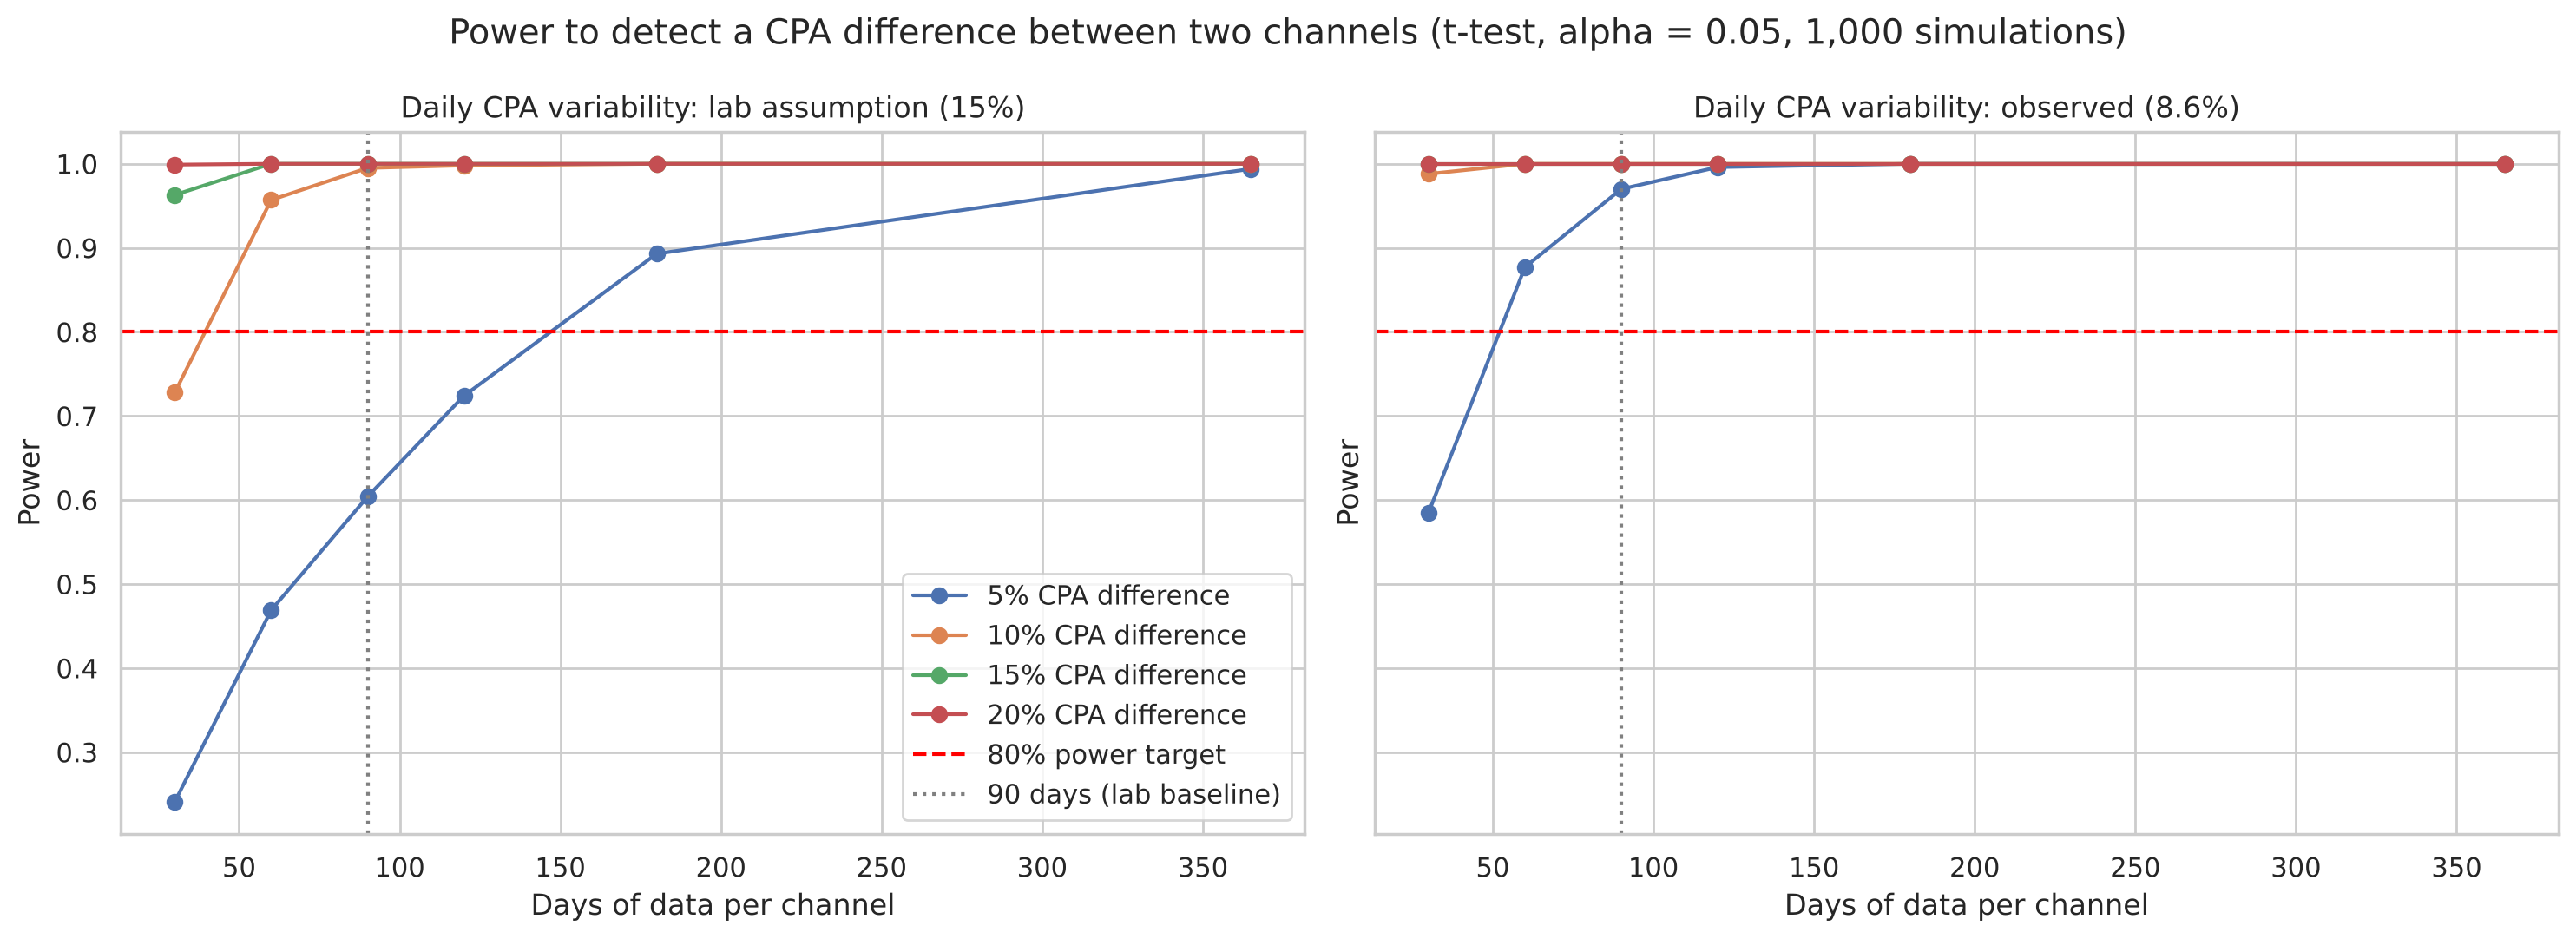

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, (label, g) in zip(axes, power_df.groupby("variability", sort=False)):
    for e, ge in g.groupby("effect_size_pct"):
        ax.plot(ge["n_days"], ge["power"], marker="o", label=f"{e}% CPA difference")
    ax.axhline(0.8, color="red", ls="--", label="80% power target")
    ax.axvline(90, color="grey", ls=":", label="90 days (lab baseline)")
    ax.set(title=f"Daily CPA variability: {label}", xlabel="Days of data per channel", ylabel="Power")
    ax.grid(True)
axes[0].legend(loc="lower right")
fig.suptitle("Power to detect a CPA difference between two channels (t-test, alpha = 0.05, 1,000 simulations)")
fig.tight_layout()
fig.savefig(FIG / "power_analysis_cpa.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
print(f"{'Variability':<24}{'Effect':>8}" + "".join(f"{n:>8}d" for n in day_grid))
for (label, e), g in power_df.groupby(["variability", "effect_size_pct"], sort=False):
    print(f"{label:<24}{e:>7}%" + "".join(f"{p:>9.1%}" for p in g.sort_values("n_days")["power"]))

Variability               Effect      30d      60d      90d     120d     180d     365d
lab assumption (15%)          5%    24.1%    46.9%    60.4%    72.4%    89.3%    99.4%
lab assumption (15%)         10%    72.8%    95.7%    99.5%    99.8%   100.0%   100.0%
lab assumption (15%)         15%    96.3%   100.0%   100.0%   100.0%   100.0%   100.0%
lab assumption (15%)         20%    99.9%   100.0%   100.0%   100.0%   100.0%   100.0%
observed (8.6%)               5%    58.5%    87.7%    97.0%    99.6%   100.0%   100.0%
observed (8.6%)              10%    98.8%   100.0%   100.0%   100.0%   100.0%   100.0%
observed (8.6%)              15%   100.0%   100.0%   100.0%   100.0%   100.0%   100.0%
observed (8.6%)              20%   100.0%   100.0%   100.0%   100.0%   100.0%   100.0%


## Step 7.2 — Minimum days for 80% power

In [6]:
def min_days(effect, cv, target=0.8, n_sim=1000, max_days=5000):
    """Smallest n (days per channel) reaching target power: doubling then binary search."""
    lo, hi = 2, 4
    while empirical_power_cpa(effect, BASE_CPA, hi, n_sim=n_sim, cv=cv) < target:
        lo, hi = hi, hi * 2
        if hi > max_days:
            return np.nan
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if empirical_power_cpa(effect, BASE_CPA, mid, n_sim=n_sim, cv=cv) >= target:
            hi = mid
        else:
            lo = mid
    return hi


TARGET = 0.80
rows = []
for cv_label, cv in [("lab assumption (15%)", 0.15), (f"observed ({OBSERVED_CV:.1%})", OBSERVED_CV)]:
    for e in effects:
        n = min_days(e, cv)
        rows.append({"variability": cv_label, "effect_size_pct": int(e * 100), "min_days_for_80pct_power": n,
                     "90_days": "sufficient" if n <= 90 else "insufficient",
                     f"{DAYS_AVAILABLE}_days": "sufficient" if n <= DAYS_AVAILABLE else "insufficient"})
min_days_df = pd.DataFrame(rows)
min_days_df.to_csv(OUT / "minimum_sample_size.csv", index=False)
min_days_df

,variability,effect_size_pct,min_days_for_80pct_power,90_days,365_days
0,lab assumption (15%),5,144,insufficient,sufficient
1,lab assumption (15%),10,37,sufficient,sufficient
2,lab assumption (15%),15,18,sufficient,sufficient
3,lab assumption (15%),20,10,sufficient,sufficient
4,observed (8.6%),5,48,sufficient,sufficient
5,observed (8.6%),10,13,sufficient,sufficient
6,observed (8.6%),15,7,sufficient,sufficient
7,observed (8.6%),20,5,sufficient,sufficient


Simulation results vary by a day or two between runs (Monte Carlo noise). The seed makes this notebook reproducible.

## Step 7.3 — Is the current data adequate for the differences we actually saw?

No CPA pair was significant after FDR correction, so there is no significant CPA pair to assess. We assess instead:
1. **The largest observed CPA gaps.** How long would we need to confirm them if they were real?
2. **The conversion-rate pairs that survived FDR (Fisher).** How much daily data would we need to see these gaps in day-to-day reporting?

Following the lab, the smaller mean is the baseline.

In [7]:
def power_for_observed(mean_a, mean_b, cv, n_days):
    base = min(mean_a, mean_b)
    diff = abs(mean_b - mean_a) / base
    return diff, empirical_power_cpa(diff, base, n_days, cv=cv)


def days_needed(diff, cv, target=0.8):
    """Analytic two-sample approximation (normal) — simulation is too slow for tiny effects."""
    z = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(target)
    return int(np.ceil(2 * (z * cv / diff) ** 2))


print("Largest observed daily-CPA gaps (none significant after FDR):")
top_cpa = cpa_results.assign(abs_pct=cpa_results["pct_difference"].abs()).nlargest(3, "abs_pct")
for _, r in top_cpa.iterrows():
    diff, pw = power_for_observed(r["mean_a"], r["mean_b"], OBSERVED_CV, DAYS_AVAILABLE)
    print(f"  {r['group_a']} vs {r['group_b']}: gap {diff:.2%}, power with {DAYS_AVAILABLE} days = {pw:.0%}, "
          f"days for 80% power = {days_needed(diff, OBSERVED_CV):,}")

daily_cr = daily.groupby("channel")["conversion_rate"]
CR_CV = (daily_cr.std() / daily_cr.mean()).mean()
print(f"\nConversion-rate pairs significant after FDR (daily conversion-rate cv = {CR_CV:.1%}):")
for _, r in fisher_results[fisher_results["significant_fdr"]].iterrows():
    base = min(r["rate_a"], r["rate_b"])
    diff = abs(r["rate_b"] - r["rate_a"]) / base
    pw = empirical_power_cpa(diff, base, DAYS_AVAILABLE, cv=CR_CV)
    print(f"  {r['group_a']} vs {r['group_b']}: gap {diff:.2%} relative, daily-level power with "
          f"{DAYS_AVAILABLE} days = {pw:.0%}, days for 80% = {days_needed(diff, CR_CV):,}")

Largest observed daily-CPA gaps (none significant after FDR):
  Instagram vs Website: gap 1.17%, power with 365 days = 44%, days for 80% power = 854
  Google Ads vs Website: gap 1.12%, power with 365 days = 44%, days for 80% power = 923


  Website vs YouTube: gap 1.00%, power with 365 days = 34%, days for 80% power = 1,171

Conversion-rate pairs significant after FDR (daily conversion-rate cv = 5.9%):
  Email vs Google Ads: gap 0.30% relative, daily-level power with 365 days = 11%, days for 80% = 6,028
  Email vs Instagram: gap 0.56% relative, daily-level power with 365 days = 24%, days for 80% = 1,708
  Email vs YouTube: gap 0.70% relative, daily-level power with 365 days = 37%, days for 80% = 1,108
  Facebook vs Instagram: gap 0.39% relative, daily-level power with 365 days = 13%, days for 80% = 3,516
  Facebook vs YouTube: gap 0.53% relative, daily-level power with 365 days = 21%, days for 80% = 1,939
  Google Ads vs Instagram: gap 0.26% relative, daily-level power with 365 days = 10%, days for 80% = 7,855
  Google Ads vs YouTube: gap 0.40% relative, daily-level power with 365 days = 16%, days for 80% = 3,412
  Instagram vs Website: gap 0.47% relative, daily-level power with 365 days = 19%, days for 80% = 2,468
  We

In [8]:
z = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(0.80)
print("Minimum detectable CPA difference at 80% power (analytic approximation):")
for label, cv in [("lab assumption (15%)", 0.15), (f"observed ({OBSERVED_CV:.1%})", OBSERVED_CV)]:
    for n in (90, DAYS_AVAILABLE):
        print(f"  {label:<22} {n:>3} days: {z * cv * np.sqrt(2 / n):.1%}")

Minimum detectable CPA difference at 80% power (analytic approximation):
  lab assumption (15%)    90 days: 6.3%
  lab assumption (15%)   365 days: 3.1%
  observed (8.6%)         90 days: 3.6%
  observed (8.6%)        365 days: 1.8%


### Key questions (Part 4)

- **Do we have enough data to detect meaningful differences?** Yes, for differences worth acting on. Under the lab's 15% assumption, 90 days detects a 10% CPA gap with high power, and 365 days detects 5%. With the variability actually observed (≈ 8.6%), even 90 days detects a 5% gap more than 80% of the time.
- **What can 90 days reliably detect?** About a 6% CPA difference at the lab's 15% variability, and about 3.6% at the observed 8.6% (minimum detectable difference printed above). A 5% gap at 15% variability needs about 144 days, so 90 days is *insufficient* for that one case.
- **How many more days for 80% power on the gaps we saw?** The largest observed CPA gaps (1.0–1.2%) would need about 850–1,200 days per channel, 2–3 years of data. The conversion-rate gaps that "survived" FDR would need 1,100–7,900 days to show up in daily reporting. In practice they can't be confirmed, and they're too small to matter.
- **Bottom line:** the absence of CPA differences isn't caused by too little data. With 365 days we had high power to find any gap of 5% or more, and found none. The channels' true CPAs are most likely within a few percent of each other.